**Eye-Tracking & Neurocognitive Intelligence | Eye-Tracking Foundations & Signal Analysis | Presented by: Reza Saadatyar (2026)**

**01 | GazeBase Source Audit and Gaze Quality**

![GazeBase audit: measured gaze trace, source sample counts, original fields and validity summary](../../images/01_source_audit_and_gaze_quality.svg)

**Objective:** Inspect source-identified eye-movement recordings, audit timestamps and gaze validity, and preserve a reusable sample-level record for subsequent preprocessing.

**Dataset:** Original GazeBase v2.0 CSV files, Round 1, Session 1; fixation (FXS), horizontal saccade (HSS), random saccade (RAN) and reading (TEX) tasks.

**Recorded scope:** The committed run selected **10 participants**, **40 task recordings** and **2,778,008 gaze samples**. Per-record valid-sample fractions ranged from **67.35% to 100%**.

**Scientific boundary:** This is an observational source audit, not event detection, a cognitive classifier or an assessment of reading performance. The introductory figure contains a measured 0–418 ms raw x/y excerpt from `S_1001_S1_FXS.csv`; the scientific plot produced below examines a longer portion of that recording.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eye_tracking_foundations")

# ---------------------------- 2. Standard Library ----------------------------
from pathlib import Path

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

# ------------------------ 5. Study Research Utilities ------------------------
from gaze_source import discover_records, load_selected_records
from gaze_quality import summarise_quality

# --------------------- 6. Output and Presentation Setup ----------------------
output_dir = root / "eye_tracking_foundations" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
plot_style(
    font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5,
    label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(10, 4),
)
print("Current outputs:", output_dir)


Repository updated.
Current outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_tracking_foundations/output


**02. Select Original GazeBase Recordings**

Select the first ten participants with complete FXS, HSS, RAN and TEX files in Round 1, Session 1. The reader recursively discovers original filenames and preserves `record_id`, participant, session, task and source-file identity. The executed run found all ten participants (Subject_1001–Subject_1010) and the resulting 40 source records.

This is a deterministic, bounded subset for the S1 methodological analysis, not a random or population-representative cohort. Other GazeBase tasks and Session 2 remain outside the present analysis. The source archive is not downloaded by this Notebook.


In [3]:
# ================== 02. Select Original GazeBase Recordings ==================

source_dir = root / "data" / "raw" / "gazebase"
MAX_PARTICIPANTS = 10
inventory = discover_records(
    source_dir, round_id=1, session_id=1,
    tasks=("FXS", "HSS", "RAN", "TEX"), max_participants=MAX_PARTICIPANTS,
)
selected_ids = sorted(inventory["participant_id"].unique().tolist())
print(f"Complete participants: {len(selected_ids)} / {MAX_PARTICIPANTS} requested")
print("Participant IDs:", ", ".join(selected_ids))
print("Source task CSV files:", len(inventory))
if len(selected_ids) < MAX_PARTICIPANTS:
    print(
        "Partial source subset: rerun Notebook 01 once all ten complete "
        "participants are available before interpreting the full-cohort study."
    )
inventory["source_dataset"] = "GazeBase"
inventory["source_archive"] = "GazeBase_v2_0.zip"
inventory["dataset_doi"] = "10.6084/m9.figshare.12912257"
inventory.drop(columns=["path"]).to_csv(output_dir / "01_source_manifest.csv", index=False)
display(inventory.drop(columns=["path"]))


Complete participants: 10 / 10 requested
Participant IDs: 001, 002, 003, 004, 005, 006, 007, 008, 009, 010
Source task CSV files: 40


,relative_file,record_id,participant_id,round_id,session_id,task,source_dataset,source_archive,dataset_doi
0,GazeBase_v2_0/Round_1/Subject_1001/S1_Fixation...,S_1001_S1_FXS,001,1,1,FXS,GazeBase,GazeBase_v2_0.zip,10.6084/m9.figshare.12912257
1,GazeBase_v2_0/Round_1/Subject_1001/S1_Horizont...,S_1001_S1_HSS,001,1,1,HSS,GazeBase,GazeBase_v2_0.zip,10.6084/m9.figshare.12912257
2,GazeBase_v2_0/Round_1/Subject_1001/S1_Random_S...,S_1001_S1_RAN,001,1,1,RAN,GazeBase,GazeBase_v2_0.zip,10.6084/m9.figshare.12912257
3,GazeBase_v2_0/Round_1/Subject_1001/S1_Reading/...,S_1001_S1_TEX,001,1,1,TEX,GazeBase,GazeBase_v2_0.zip,10.6084/m9.figshare.12912257
4,GazeBase_v2_0/Round_1/Subject_1002/S1_Fixation...,S_1002_S1_FXS,002,1,1,FXS,GazeBase,GazeBase_v2_0.zip,10.6084/m9.figshare.12912257
5,GazeBase_v2_0/Round_1/Subject_1002/S1_Horizont...,S_1002_S1_HSS,002,1,1,HSS,GazeBase,GazeBase_v2_0.zip,10.6084/m9.figshare.12912257
6,GazeBase_v2_0/Round_1/Subject_1002/S1_Random_S...,S_1002_S1_RAN,002,1,1,RAN,GazeBase,GazeBase_v2_0.zip,10.6084/m9.figshare.12912257
7,GazeBase_v2_0/Round_1/Subject_1002/S1_Reading/...,S_1002_S1_TEX,002,1,1,TEX,GazeBase,GazeBase_v2_0.zip,10.6084/m9.figshare.12912257
8,GazeBase_v2_0/Round_1/Subject_1003/S1_Fixation...,S_1003_S1_FXS,003,1,1,FXS,GazeBase,GazeBase_v2_0.zip,10.6084/m9.figshare.12912257
9,GazeBase_v2_0/Round_1/Subject_1003/S1_Horizont...,S_1003_S1_HSS,003,1,1,HSS,GazeBase,GazeBase_v2_0.zip,10.6084/m9.figshare.12912257


**03. Read Original Sample Columns and Record Identities**

Read each CSV without changing its source timebase or gaze units. The main fields are `n` (timestamp in milliseconds), `x` and `y` (horizontal and vertical gaze position in degrees of visual angle) and `val` (source validity: zero denotes a valid recording sample). When present, `xT` and `yT` give the horizontal and vertical **stimulus target positions**, not additional eye measurements; target fields are unavailable (NaN) for tasks without a target, including reading (TEX). The optional `dP` field stores uncalibrated pupil area, while `lab` holds vendor parser codes where provided.

The derived `sample_valid` indicator requires both `val = 0` and finite `x/y`. It describes usable gaze samples, not a manually adjudicated fixation or saccade. Retain original columns and the source filename, `record_id`, `participant_id` and `sample_index` in `01_gaze_samples.csv` so Notebook 02 can reuse the same records without reopening the archive.

**Source variable dictionary:** [GazeBase dataset publication](https://doi.org/10.1038/s41597-021-00959-y), Table 4.


In [4]:
# ========== 03. Read Original Sample Columns and Record Identities ===========

samples = load_selected_records(inventory)
assert not samples.duplicated(["record_id", "sample_index"]).any()
samples.to_csv(output_dir / "01_gaze_samples.csv", index=False)
print(f"Records: {len(inventory)}, raw samples: {len(samples):,}")
display(samples.head(8))


Records: 40, raw samples: 2,778,008


,sample_index,n,x,y,val,xT,yT,dP,lab,sample_valid,source,source_archive,record_id,participant_id,round_id,session_id,task,source_file,time_s
0,0,0,1.025671,-3.618744,0,-0.220439,-0.081702,2614.0,0,True,GazeBase,GazeBase_v2_0.zip,S_1001_S1_FXS,001,1,1,FXS,GazeBase_v2_0/Round_1/Subject_1001/S1_Fixation...,0.000
1,1,1,1.025671,-3.615809,0,-0.220439,-0.081702,2614.0,0,True,GazeBase,GazeBase_v2_0.zip,S_1001_S1_FXS,001,1,1,FXS,GazeBase_v2_0/Round_1/Subject_1001/S1_Fixation...,0.001
2,2,2,1.034486,-3.615809,0,-0.220439,-0.081702,2613.0,0,True,GazeBase,GazeBase_v2_0.zip,S_1001_S1_FXS,001,1,1,FXS,GazeBase_v2_0/Round_1/Subject_1001/S1_Fixation...,0.002
3,3,3,1.049177,-3.609939,0,-0.220439,-0.081702,2612.0,0,True,GazeBase,GazeBase_v2_0.zip,S_1001_S1_FXS,001,1,1,FXS,GazeBase_v2_0/Round_1/Subject_1001/S1_Fixation...,0.003
4,4,4,1.060930,-3.601134,0,-0.220439,-0.081702,2612.0,0,True,GazeBase,GazeBase_v2_0.zip,S_1001_S1_FXS,001,1,1,FXS,GazeBase_v2_0/Round_1/Subject_1001/S1_Fixation...,0.004
5,5,5,1.057991,-3.601134,0,-0.220439,-0.081702,2612.0,0,True,GazeBase,GazeBase_v2_0.zip,S_1001_S1_FXS,001,1,1,FXS,GazeBase_v2_0/Round_1/Subject_1001/S1_Fixation...,0.005
6,6,6,1.052115,-3.607004,0,-0.220439,-0.081702,2613.0,0,True,GazeBase,GazeBase_v2_0.zip,S_1001_S1_FXS,001,1,1,FXS,GazeBase_v2_0/Round_1/Subject_1001/S1_Fixation...,0.006
7,7,7,1.055053,-3.615809,0,-0.220439,-0.081702,2614.0,1,True,GazeBase,GazeBase_v2_0.zip,S_1001_S1_FXS,001,1,1,FXS,GazeBase_v2_0/Round_1/Subject_1001/S1_Fixation...,0.007


**04. Audit Sampling and Missingness**

Summarise source time intervals, duplicate or reversed timestamp steps, long gaps, sample validity, finite pupil-area coverage and available vendor labels for **each recording**. The observed median interval is calculated from positive timestamp differences. For this descriptive audit, a **large gap** is an interval greater than **three times that recording's median positive interval** (`gap_multiplier=3.0`). This is distinct from Notebook 02's fixed **5-ms continuity rule** for preprocessing.

The committed Notebook 01 execution contains **2,778,008 samples from 40 recordings**. Observed `valid_fraction` values range from approximately **0.6735 to 1.0000** across records. These are the recorded extremes, not a full distribution or an instrument-accuracy estimate. Poor-quality recordings remain in the audit; none are silently excluded.


In [5]:
# ==================== 04. Audit Sampling and Missingness =====================

quality = summarise_quality(samples)
quality.to_csv(output_dir / "01_quality_by_record.csv", index=False)
display(quality)


,record_id,participant_id,round_id,session_id,task,n_samples,duration_s,n_valid,valid_fraction,invalid_fraction,n_duplicate_or_reversed_steps,median_interval_ms,observed_rate_hz,n_large_gaps,pupil_finite_fraction,vendor_label_fraction
0,S_1001_S1_FXS,001,1,1,FXS,15077,15.076,14588,0.967566,0.032434,0,1.0,1000.0,0,0.967566,1.0
1,S_1001_S1_HSS,001,1,1,HSS,101299,101.298,100933,0.996387,0.003613,0,1.0,1000.0,0,0.996387,1.0
2,S_1001_S1_RAN,001,1,1,RAN,101204,101.203,99866,0.986779,0.013221,0,1.0,1000.0,0,0.986779,1.0
3,S_1001_S1_TEX,001,1,1,TEX,60233,60.232,58228,0.966713,0.033287,0,1.0,1000.0,0,0.966713,1.0
4,S_1002_S1_FXS,002,1,1,FXS,15074,15.073,14597,0.968356,0.031644,0,1.0,1000.0,0,0.968356,1.0
5,S_1002_S1_HSS,002,1,1,HSS,101313,101.312,100397,0.990959,0.009041,0,1.0,1000.0,0,0.990959,1.0
6,S_1002_S1_RAN,002,1,1,RAN,101299,101.298,100374,0.990869,0.009131,0,1.0,1000.0,0,0.990869,1.0
7,S_1002_S1_TEX,002,1,1,TEX,60237,60.236,59367,0.985557,0.014443,0,1.0,1000.0,0,0.985557,1.0
8,S_1003_S1_FXS,003,1,1,FXS,15074,15.073,14872,0.986599,0.013401,0,1.0,1000.0,0,0.986599,1.0
9,S_1003_S1_HSS,003,1,1,HSS,101332,101.331,101071,0.997424,0.002576,0,1.0,1000.0,0,0.997424,1.0


**05. Visualise Recorded Gaze and Quality**

The generated plot uses the first **10,000 source samples** from one selected record. Its upper panel shows original horizontal and vertical gaze coordinates (dva), while the lower panel shows the source-derived binary `sample_valid` indicator over elapsed time. This is an exploratory quality inspection and does not identify confirmed movement events, attention or reading comprehension.

The introductory SVG uses a separate measured **0–418 ms** excerpt from `S_1001_S1_FXS.csv`, displaying every fourth sample for legibility. That figure is an illustration of **actual source data**, not a substitute for the longer Notebook plot or the complete record-quality table.


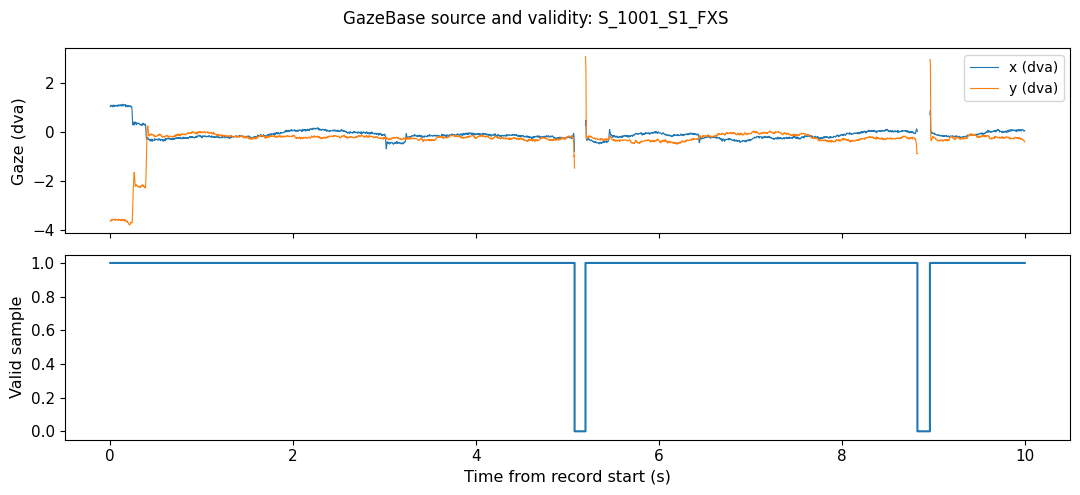

In [6]:
# ================== 05. Visualise Recorded Gaze and Quality ==================

record_id = str(inventory.iloc[0].record_id)
trace = samples[samples.record_id.eq(record_id)].head(10000)
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(trace.time_s, trace.x, lw=0.8, label="x (dva)")
axes[0].plot(trace.time_s, trace.y, lw=0.8, label="y (dva)")
axes[0].set_ylabel("Gaze (dva)")
axes[0].legend(loc="upper right")
axes[1].step(trace.time_s, trace.sample_valid.astype(int), where="post")
axes[1].set_ylabel("Valid sample")
axes[1].set_xlabel("Time from record start (s)")
fig.suptitle(f"GazeBase source and validity: {record_id}")
fig.tight_layout()
save_figure(fig, output_dir / "01_gaze_quality.png")
plt.show()


**06. Scientific Summary and Output Download**

Notebook 01 saves `01_source_manifest.csv`, `01_gaze_samples.csv`, `01_quality_by_record.csv` and `01_gaze_quality.png`. The source manifest records file identities; the large sample CSV preserves the raw gaze representation; the quality table and figure document the source audit. These are the **Notebook 01 outputs**.

Notebook 02 consumes the current sample CSV and manifest and checks the quality-table record counts before processing. If the Colab runtime changes, use the ZIP created by the unchanged `download_outputs_from_colab()` helper; this is a file-transfer package, not a separate scientific result. Keep the large generated CSV and ZIP outside GitHub. Notebook 01 does **not** need to be rerun when only Markdown and the editable introductory SVG change.


In [7]:
# ================ 06. Scientific Summary and Output Download =================

print("Saved source manifest, raw sample table, record quality and evidence plot.")
print("Observed participants:", quality.participant_id.nunique())
print("Valid-sample range:", quality.valid_fraction.min(), quality.valid_fraction.max())
download_outputs_from_colab(
    "eye_tracking_foundations/output", "01"
)


Saved source manifest, raw sample table, record quality and evidence plot.
Observed participants: 10
Valid-sample range: 0.6735225355863987 1.0
------------------------------------------------------------------------
Notebook 01
Files packaged: 4
  + 01_gaze_quality.png
  + 01_gaze_samples.csv
  + 01_quality_by_record.csv
  + 01_source_manifest.csv
Download ZIP from Colab Contents: /content/eye_tracking_foundations_Notebook_01_Outputs.zip
